<a href="https://colab.research.google.com/github/TheLedAlchemist/arena-selfstudy/blob/main/raytracing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install jaxtyping

In [3]:
import os
import sys
from functools import partial
from pathlib import Path
from typing import Callable

import einops
import plotly.express as px
import plotly.graph_objects as go
import torch as t
from IPython.display import display
from ipywidgets import interact
from jaxtyping import Bool, Float
from torch import Tensor
from tqdm.auto import tqdm

# Make sure exercises are in the path
chapter = "chapter0_fundamentals"
section = "part1_ray_tracing"

# Clone the repo if we are in Colab and it doesn't exist
if not Path(chapter).exists():
    !git clone https://github.com/callummcdougall/ARENA_3.0.git
    # Move or symlink files if necessary, or update root_dir to the cloned repo
    if Path("ARENA_3.0").exists():
        sys.path.append(str(Path.cwd() / "ARENA_3.0" / chapter / "exercises"))
        root_dir = Path.cwd() / "ARENA_3.0"
else:
    try:
        root_dir = next(p for p in Path.cwd().parents if (p / chapter).exists())
    except StopIteration:
        root_dir = Path.cwd()
    exercises_dir = root_dir / chapter / "exercises"
    if str(exercises_dir) not in sys.path:
        sys.path.append(str(exercises_dir))

try:
    import part1_ray_tracing.tests as tests
    from part1_ray_tracing.utils import (
        render_lines_with_plotly,
        setup_widget_fig_ray,
        setup_widget_fig_triangle,
    )
    from plotly_utils import imshow
except ModuleNotFoundError:
    # Fallback to importing directly from the repo's path structure if needed
    sys.path.append(str(Path.cwd() / "ARENA_3.0" / chapter / "exercises"))
    import part1_ray_tracing.tests as tests
    from part1_ray_tracing.utils import (
        render_lines_with_plotly,
        setup_widget_fig_ray,
        setup_widget_fig_triangle,
    )
    from plotly_utils import imshow

MAIN = __name__ == "__main__"

Cloning into 'ARENA_3.0'...
remote: Enumerating objects: 36563, done.
remote: Counting objects: 100% (681/681), done.
remote: Compressing objects: 100% (333/333), done.
remote: Total 36563 (delta 544), reused 348 (delta 348), pack-reused 35882 (from 2)
Receiving objects: 100% (36563/36563), 227.74 MiB | 16.43 MiB/s, done.
Resolving deltas: 100% (24038/24038), done.


In [4]:
from google.colab import output
output.enable_custom_widget_manager()

In [5]:
import os
from pathlib import Path

# Change directory to the exercises subfolder so that Path.cwd().parents contains the root repository directory
correct_dir = "/content/ARENA_3.0/chapter0_fundamentals/exercises"
if Path(correct_dir).exists():
    os.chdir(correct_dir)

def make_rays_1d(num_pixels: int, y_limit: float) -> Tensor:
    """
    num_pixels: The number of pixels in the y dimension. Since there is one ray per pixel, this is
        also the number of rays.
    y_limit: At x=1, the rays should extend from -y_limit to +y_limit, inclusive of both endpoints.

    Returns: shape (num_pixels, num_points=2, num_dim=3) where the num_points dimension contains
        (origin, direction) and the num_dim dimension contains xyz.

    Example of make_rays_1d(9, 1.0): [
        [[0, 0, 0], [1, -1.0, 0]],
        [[0, 0, 0], [1, -0.75, 0]],
        [[0, 0, 0], [1, -0.5, 0]],
        ...
        [[0, 0, 0], [1, 0.75, 0]],
        [[0, 0, 0], [1, 1, 0]],
    ]
    """
    # Create an empty tensor of shape (num_pixels, 2, 3)
    rays = t.zeros((num_pixels, 2, 3))
    # Set the x coordinate of direction (point 1) to 1
    rays[:, 1, 0] = 1.0
    # Generate linear spacing for the y-coordinates from -y_limit to +y_limit
    y_coordinates = t.linspace(-y_limit, y_limit, num_pixels)
    # Assign the y coordinates to the direction (point 1, dimension 1)
    rays[:, 1, 1] = y_coordinates
    return rays

# Run tests and visualize
tests.test_make_rays_1d(make_rays_1d)

rays1d = make_rays_1d(9, 10.0)
fig = render_lines_with_plotly(rays1d)

All tests in `test_make_rays_1d` passed!


# Part 1

In [54]:
def intersect_ray_1d(ray: Float[Tensor, "points dims"], segment: Float[Tensor, "points dims"]) -> bool:
    """
    ray: shape (n_points=2, n_dim=3)  # O, D points
    segment: shape (n_points=2, n_dim=3)  # L_1, L_2 points

    Return True if the ray intersects the segment.
    """

    # Toss the last component of n_dim rq
    ray = ray[:, :-1]
    segment = segment[:, :-1]

    A = t.stack([ray[1], segment[0] - segment[1]], dim = 1)
    b = segment[0] - ray[0]

    try:
      x = t.linalg.solve(A, b)
    except RuntimeError:
      # Bruh i forgot the matrices could be singular
      return False

    return (x[0].item() >= 0) and (x[1].item() >= 0) and (x[1].item() <= 1)

tests.test_intersect_ray_1d(intersect_ray_1d)
tests.test_intersect_ray_1d_special_case(intersect_ray_1d)


All tests in `test_intersect_ray_1d` passed!
All tests in `test_intersect_ray_1d_special_case` passed!


In [55]:
def make_rays_2d(num_pixels_y: int, num_pixels_z: int, y_limit: float, z_limit: float) -> Float[Tensor, "nrays 2 3"]:
    """
    num_pixels_y: The number of pixels in the y dimension
    num_pixels_z: The number of pixels in the z dimension

    y_limit: At x=1, the rays should extend from -y_limit to +y_limit, inclusive of both.
    z_limit: At x=1, the rays should extend from -z_limit to +z_limit, inclusive of both.

    Returns: shape (num_rays=num_pixels_y * num_pixels_z, num_points=2, num_dims=3).
    """
    n_pixels = num_pixels_y * num_pixels_z
    ygrid = t.linspace(-y_limit, y_limit, num_pixels_y)
    zgrid = t.linspace(-z_limit, z_limit, num_pixels_z)
    rays = t.zeros((n_pixels, 2, 3), dtype=t.float32)
    rays[:, 1, 0] = 1
    rays[:, 1, 1] = einops.repeat(ygrid, "y -> (y z)", z=num_pixels_z)
    rays[:, 1, 2] = einops.repeat(zgrid, "z -> (y z)", y=num_pixels_y)
    return rays

# Part 2

In [6]:
def intersect_rays_1d(
    rays: Float[Tensor, "nrays 2 3"], segments: Float[Tensor, "nsegments 2 3"]
) -> Bool[Tensor, " nrays"]:
  """
  Determine whether each ray intersects a segment.
  """

  # Idk man I'm just tryna do some type enforcing
  assert isinstance(rays, t.Tensor)
  assert isinstance(segments, t.Tensor)

  # Maybe some dim stuff as well?
  assert rays.shape[-1] == 3
  assert segments.shape[-1] == 3
  assert rays.shape[1] == 2
  assert segments.shape[1] == 2

  # Toss the last component of n_dim rq but like it's a 3d tensor now
  ray = rays[..., :-1]
  segment = segments[..., :-1]
  # I'm reusing names from the previous part

  # Lowkey need broadcasting to get this done!
  segment = einops.repeat(segment, "b c d -> repeat b c d", repeat=ray.shape[0])
  ray = einops.repeat(ray, "b c d -> b repeat c d", repeat=segment.shape[1])

  # I reused stacking logic from above, just using the : as needed
  A = t.stack([ray[..., 1, :], segment[..., 0, :] - segment[..., 1, :]], dim = -1)
  b = segment[..., 0, :] - ray[..., 0, :]

  # This makes a mask that says whenever the determinant is smol at a given
  # index in dimension 0 of the A matrix
  id_mask = t.abs(t.linalg.det(A)) < 1e-6

  # Give me the batch indices where the det is small and set to the 2x2 id. lol
  A[id_mask, ...] = t.eye(2)

  # try:
  x = t.linalg.solve(A, b)
  # except RuntimeError:
  #   # Bruh i forgot the matrices could be singular
  #   return False

  # Literally just converting the logic from the prev function
  # into tensor ops and a .any at the end...
  print(f"x: {x.shape}")
  bools = (x[..., 0] >= 0) & (x[..., 1] >= 0) & (x[..., 1] <= 1)
  print(f"Bools: {bools.shape}\nMask: {id_mask.shape}")
  return t.any(bools & ~id_mask, dim = 1)

In [ ]:
tests.test_intersect_rays_1d(intersect_rays_1d)
tests.test_intersect_rays_1d_special_case(intersect_rays_1d)

In [ ]:
# testing my indexing rq...
test1 = t.Tensor([[[1, 2, 3], [4, 5, 6]]])
test1, test1[:, :, 1], test1[:, :, :-1]

(tensor([[[1., 2., 3.],
          [4., 5., 6.]]]),
 tensor([[2., 5.]]),
 tensor([[[1., 2.],
          [4., 5.]]]))

In [ ]:
# Prototyping some ideas around masking and setting to 2x2 ID that way...
test1 = t.Tensor([[[1, 2, 3], [4, 5, 6]], [[1, 2, 3], [4, 5, 6]]])[..., :-1]
t.abs(t.linalg.det(test1)) < 1e-6, test1[t.abs(t.linalg.det(test1)) > 1e-6, ...]

(tensor([False, False]),
 tensor([[[1., 2.],
          [4., 5.]],
 
         [[1., 2.],
          [4., 5.]]]))

# Triangles

In [7]:
one_triangle = t.tensor([[0, 0, 0], [4, 0.5, 0], [2, 3, 0]])
A, B, C = one_triangle
x, y, z = one_triangle.T

fig: go.FigureWidget = setup_widget_fig_triangle(x, y, z)
display(fig)


@interact(u=(-0.5, 1.5, 0.01), v=(-0.5, 1.5, 0.01))
def update(u=0.0, v=0.0):
    P = A + u * (B - A) + v * (C - A)
    fig.update_traces({"x": [P[0]], "y": [P[1]]}, 2)


FigureWidget({
    'data': [{'marker': {'size': 12},
              'mode': 'markers+text',
              'text': [A, B, C],
              'textfont': {'size': 18},
              'textposition': 'middle left',
              'type': 'scatter',
              'uid': '7fccb04f-2c62-462d-b25e-2919e75f780f',
              'x': array([0., 4., 2.], dtype=float32),
              'y': array([0. , 0.5, 3. ], dtype=float32)},
             {'mode': 'lines',
              'type': 'scatter',
              'uid': '4f9930d9-b9cf-4934-93ff-12e43d1030cc',
              'x': [0.0, 4.0, 2.0, 0.0],
              'y': [0.0, 0.5, 3.0, 0.0]},
             {'marker': {'size': 12, 'symbol': 'x'},
              'mode': 'markers',
              'type': 'scatter',
              'uid': 'f75e6f36-ea0e-4a72-9f8e-6567f6c19308',
              'x': [],
              'y': []}],
    'layout': {'height': 400,
               'margin': {'b': 10, 'l': 40, 't': 60},
               'showlegend': False,
               'template': 

interactive(children=(FloatSlider(value=0.0, description='u', max=1.5, min=-0.5, step=0.01), FloatSlider(value…

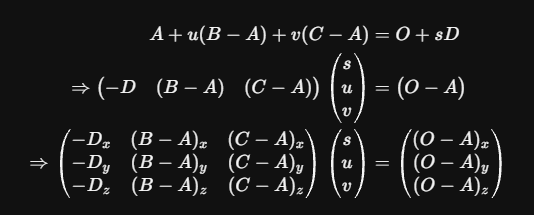

In [20]:
Point = Float[Tensor, "points=3"]


def triangle_ray_intersects(A: Point, B: Point, C: Point, O: Point, D: Point) -> bool:
    """
    A: shape (3,), one vertex of the triangle
    B: shape (3,), second vertex of the triangle
    C: shape (3,), third vertex of the triangle
    O: shape (3,), origin point
    D: shape (3,), direction point

    Return True if the ray and the triangle intersect.
    """

    A_matrix = t.stack([-D, B-A, C-A], dim=1)

    if t.abs(t.linalg.det(A_matrix)) < 1e-6:
      return False

    # print(O.shape, A.shape)
    # print(A.shape, (O-A).shape)

    coords = t.linalg.solve(A_matrix, O-A)
    # print(coords.shape)
    # print(coords)

    s, u, v = coords
    return bool((s >= 0) and (u >= 0) and (v >= 0) and (u + v <= 1))


tests.test_triangle_ray_intersects(triangle_ray_intersects)


All tests in `test_triangle_ray_intersects` passed!


In [56]:
def raytrace_triangle(
    rays: Float[Tensor, "nrays rayPoints=2 dims=3"],
    triangle: Float[Tensor, "trianglePoints=3 dims=3"],
) -> Bool[Tensor, " nrays"]:
    """
    For each ray, return True if the triangle intersects that ray.
    """
    rays_ext = einops.repeat(rays, "nrays points dims -> nrays points dims")
    triangle_view = einops.repeat(triangle, "points dims -> (repeat) points dims", repeat=rays.shape[0])

    # direction (D) is in rays[:, i, :], I want [:, 1, :] - [:, 0, :]
    # A, B, C are triangle_view[:, 0, :], triangle_view[:, 1, :], triangle_view[:, 2, :]

    # A_matrix = t.stack(
    #     [-(rays_ext[:, 1, :] - rays_ext[:, 0, :]),
    #      triangle[1, :] - triangle[0, :],
    #      triangle[2, :] - triangle[0, :]], dim=-1
    # )

    A_matrix = t.stack(
        [-rays_ext[:, 1, :],
         triangle_view[:, 1, :] - triangle_view[:, 0, :],
         triangle_view[:, 2, :] - triangle_view[:, 0, :]], dim=-1
    )

    # print(A_matrix.shape)

    mask = t.abs(t.linalg.det(A_matrix)) < 1e-6
    # print(mask.shape)

    A_matrix[mask, ...] = t.eye(3)

    solutions = t.linalg.solve(A_matrix, rays_ext[:, 0, :] - triangle[0, :])
    # print(solutions.shape)

    # print((solutions[:, 1] + solutions[:, 2] <= 1).shape)
    # print(t.all(solutions >= 0, dim=1).shape)

    bools = t.all(solutions >= 0, dim=1) & (solutions[:, 1] + solutions[:, 2] <= 1)

    # Need to preserve the same s, u, v checking logic here
    return bools & ~mask

tests.test_raytrace_triangle(raytrace_triangle)

A = t.tensor([1, 0.0, -0.5])
B = t.tensor([1, -0.5, 0.0])
C = t.tensor([1, 0.5, 0.5])
num_pixels_y = num_pixels_z = 15
y_limit = z_limit = 0.5

# Plot triangle & rays
test_triangle = t.stack([A, B, C], dim=0)
rays2d = make_rays_2d(num_pixels_y, num_pixels_z, y_limit, z_limit)
triangle_lines = t.stack([A, B, C, A, B, C], dim=0).reshape(-1, 2, 3)
render_lines_with_plotly(rays2d, triangle_lines)

# Calculate and display intersections
intersects = raytrace_triangle(rays2d, test_triangle)
img = intersects.reshape(num_pixels_y, num_pixels_z).int()
imshow(img, origin="lower", width=600, title="Triangle (as intersected by rays)")


All tests in `test_raytrace_triangle` passed!


# Mesh Rendering

In [64]:
triangles = t.load("part1_ray_tracing/pikachu.pt", weights_only=True)

In [67]:
def raytrace_mesh(
    rays: Float[Tensor, "nrays rayPoints=2 dims=3"],
    triangles: Float[Tensor, "ntriangles trianglePoints=3 dims=3"],
) -> Float[Tensor, " nrays"]:
    """
    For each ray, return the distance to the closest intersecting triangle, or infinity.
    """
    rays_ext = einops.repeat(rays, "nrays points dims -> nrays (repeat) points dims", repeat=triangles.shape[0])
    triangle_view = einops.repeat(triangles, "ntriangles points dims -> (repeat) ntriangles points dims", repeat=rays.shape[0])

    A_matrix = t.stack(
        [-rays_ext[..., 1, :],
         triangle_view[..., 1, :] - triangle_view[..., 0, :],
         triangle_view[..., 2, :] - triangle_view[..., 0, :]], dim=-1
    )

    mask = t.abs(t.linalg.det(A_matrix)) < 1e-6
    A_matrix[mask, ...] = t.eye(3)
    solutions = t.linalg.solve(A_matrix, rays_ext[..., 0, :] - triangles[..., 0, :])

    bools = t.all(solutions >= 0, dim=-1) & (solutions[..., 1] + solutions[..., 2] <= 1)

    # Need to preserve the same s, u, v checking logic here
    hits = bools & ~mask

    # Scale s by the x component of D
    # t.where is pretty cool, claude helped me out with that part
    dists = t.where(hits, solutions[..., 0] * rays_ext[..., 1, 0], t.inf)
    return einops.reduce(dists, "NR NT -> NR", "min")


tests.test_raytrace_mesh(raytrace_mesh)

num_pixels_y = 120
num_pixels_z = 120
y_limit = z_limit = 1

rays = make_rays_2d(num_pixels_y, num_pixels_z, y_limit, z_limit)
rays[:, 0] = t.tensor([-2, 0.0, 0.0])
dists = raytrace_mesh(rays, triangles)
intersects = t.isfinite(dists).view(num_pixels_y, num_pixels_z)
dists_square = dists.view(num_pixels_y, num_pixels_z)
img = t.stack([intersects, dists_square], dim=0)

fig = px.imshow(img, facet_col=0, origin="lower", color_continuous_scale="magma", width=1000)
fig.update_layout(coloraxis_showscale=False)
for i, text in enumerate(["Intersects", "Distance"]):
    fig.layout.annotations[i]["text"] = text
fig.show()

All tests in `test_raytrace_mesh` passed!


AttributeError: 'Figure' object has no attribute 'save'